# Non-Probabilistic Design: Interval Analysis and Worst-Case Optimization

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Ahmed-Bayoumy/MECH559/blob/HEAD/L14/L14_interval_worst_case_optimization.ipynb)
### MECH 559 - Systems Optimization - L14
### Course Instructor: Dr. Ahmed Bayoumy
Author of the notebook: Dr. Ahmed Bayoumy

Companion notebook to the "Non-probabilistic approaches" slide. When data is too
scarce to justify a probability distribution (epistemic uncertainty), the honest
move is to bound the uncertain quantity in an interval or convex set instead, and
design for the *worst* realization in that set:

$$
\min_x \max_{u\in\mathcal U} f(x,u) \quad\text{s.t.}\quad \max_{u\in\mathcal U} g_j(x,u)\le0.
$$

This notebook works a closed-form interval example, then builds a genuine nested
min-max: an outer `scipy.optimize.minimize` whose constraint is itself the result
of an inner maximization over the uncertainty interval.

## Learning objectives

1. Size a simple structural member for a *nominal* load vs. the *worst-case* load
   in an interval, and quantify the "price" of the worst-case guarantee.
2. Recognize that the maximum of a convex function over an interval always sits
   at an interval endpoint -- a useful shortcut for many worst-case constraints.
3. Build and solve a genuine nested min-max problem (obstacle-avoidance under
   positional uncertainty) where the worst case is *not* always at an endpoint,
   verifying the numerical inner search against a closed form.
4. Compare the worst-case design's cost to the deterministic design's cost, and
   discuss when a probabilistic (RBDO/RDO) approach would recover some of that
   cost instead.

> **Classroom rhythm:** pause at each **Predict** prompt before running the next
> cell.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize, minimize_scalar

plt.rcParams.update({
    "font.size": 11,
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.25,
})
COLORS = {"det": "#D1495B", "wc": "#2A9D5C", "sweep": "#D1495B22", "nominal": "#264653"}
rng = np.random.default_rng(559)
print(f"NumPy {np.__version__}")

NumPy 2.5.2


---
## 1. Sizing a rod: nominal load vs. worst-case load

A rod carries an axial load known only to lie in an interval (e.g. from a handful
of test measurements, not enough to fit a distribution): $P\in[P_L,P_U]$. Stress
is $\sigma(x)=P/x$ for cross-sectional area $x$; the allowable stress is
$\sigma_{\text{allow}}$.

> **Predict:** sizing for the *nominal* (midpoint) load and sizing for the
> *worst-case* (upper bound) load -- roughly how much extra area does the
> worst-case design need here?

nominal-load design area:  x_det = 0.5750 in^2
worst-case design area:    x_wc  = 0.7500 in^2   (+30.4% material)


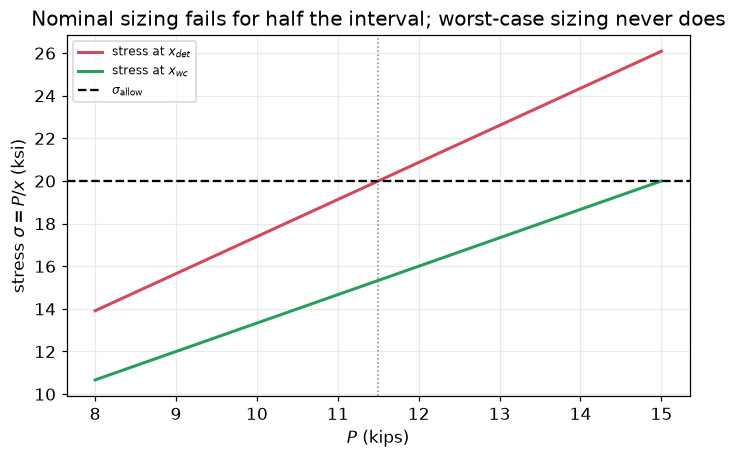


stress at x_det for P=P_U: 26.09 ksi  (allowable 20.0: VIOLATED)
stress at x_wc  for P=P_U: 20.00 ksi  (allowable 20.0: OK)


In [2]:
sigma_allow = 20.0     # ksi
P_L, P_U = 8.0, 15.0   # kips, interval only -- no distribution assumed
P_nominal = 0.5 * (P_L + P_U)

x_det = P_nominal / sigma_allow
x_wc = P_U / sigma_allow

print(f"nominal-load design area:  x_det = {x_det:.4f} in^2")
print(f"worst-case design area:    x_wc  = {x_wc:.4f} in^2   (+{100*(x_wc/x_det - 1):.1f}% material)")

Ps = np.linspace(P_L, P_U, 200)
fig, ax = plt.subplots(figsize=(6.5, 4.3))
ax.plot(Ps, Ps / x_det, color=COLORS["det"], lw=2, label=r"stress at $x_{det}$")
ax.plot(Ps, Ps / x_wc, color=COLORS["wc"], lw=2, label=r"stress at $x_{wc}$")
ax.axhline(sigma_allow, color="black", ls="--", label=r"$\sigma_{\rm allow}$")
ax.axvline(P_nominal, color="gray", ls=":", lw=1)
ax.set(xlabel="$P$ (kips)", ylabel=r"stress $\sigma=P/x$ (ksi)",
       title="Nominal sizing fails for half the interval; worst-case sizing never does")
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

print(f"\nstress at x_det for P=P_U: {P_U/x_det:.2f} ksi  (allowable {sigma_allow}: "
      f"{'OK' if P_U/x_det <= sigma_allow else 'VIOLATED'})")
print(f"stress at x_wc  for P=P_U: {P_U/x_wc:.2f} ksi  (allowable {sigma_allow}: "
      f"{'OK' if P_U/x_wc <= sigma_allow else 'VIOLATED'})")

The nominal design is exactly at the allowable stress only for $P=P_{\text{nominal}}$
and is over-stressed for every $P$ above it -- roughly half the interval, with no
distribution to say how likely that half is. The worst-case design stays at or
under the allowable stress for *every* $P$ in $[P_L,P_U]$, at the cost of extra
material. This is the whole idea of the slide's min-max formulation, in the
simplest possible (closed-form) case.

---
## 2. A genuine nested min-max: obstacle avoidance under positional uncertainty

Now a case where the worst case is not simply "plug in the upper bound." A
design point $\mathbf x=(x_1,x_2)$ must stay outside a circular keep-out zone of
radius $r$, whose center is on the $x_1$-axis at an uncertain position
$u\in[u_L,u_U]$ (known only within an interval -- e.g. an obstacle whose exact
position was measured with limited precision):

$$
h(\mathbf x,u) = r^2-(x_1-u)^2-x_2^2 \le 0 \quad\text{(feasible: outside the circle)}.
$$

$h$ is *concave* in $u$ (it is $r^2-(x_1-u)^2-x_2^2$, and $-(x_1-u)^2$ is
concave), so its maximum over $u\in[u_L,u_U]$ can land in the *interior* of the
interval, not just at an endpoint -- unlike Section 1.

> **Predict:** for a fixed $\mathbf x$, is the worst-case obstacle position
> $u^\*$ always $u_L$ or $u_U$, or could it be somewhere in between?

In [3]:
r = 1.5
u_L, u_U = -1.0, 1.0

def h(u, x):
    return r ** 2 - (x[0] - u) ** 2 - x[1] ** 2

def worst_case_h_numeric(x):
    res = minimize_scalar(lambda u: -h(u, x), bounds=(u_L, u_U), method="bounded")
    return -res.fun

def worst_case_h_closed_form(x):
    u_star = np.clip(x[0], u_L, u_U)   # dh/du=0 at u=x1 (interior stationary point of a concave fn)
    return h(u_star, x)

for x_test in ([0.4, 0.9], [2.0, 0.5], [-3.0, 1.0]):
    num = worst_case_h_numeric(x_test)
    cf = worst_case_h_closed_form(x_test)
    print(f"x={x_test}:  numeric inner max = {num:.5f}   closed-form = {cf:.5f}   match: {np.isclose(num, cf)}")

x=[0.4, 0.9]:  numeric inner max = 1.44000   closed-form = 1.44000   match: True
x=[2.0, 0.5]:  numeric inner max = 0.99999   closed-form = 1.00000   match: True
x=[-3.0, 1.0]:  numeric inner max = -2.75002   closed-form = -2.75000   match: True


The numerical inner search (`minimize_scalar` over the interval) agrees with the
closed form to solver tolerance for every test point, including the first one
where the worst case is interior to $[u_L,u_U]$ (not at an endpoint) -- exactly
what the concavity argument predicted. This is the same trust-but-verify step
used for FORM in the previous notebook: check the numerical machinery against a
case with a known answer before relying on it where no closed form exists.

---
## 3. Solving the outer problem: deterministic vs. worst-case design

$$
\min_{\mathbf x}\; f(\mathbf x)=x_1^2+x_2^2 \quad\text{s.t. stay outside the keep-out zone}
$$

Two versions of the constraint: the **deterministic** one assumes the obstacle
sits at its nominal position $u=0$; the **worst-case** one uses
`worst_case_h_numeric` from Section 2 -- so every evaluation of the outer
constraint triggers an inner optimization, the min-max structure from the slide.

deterministic (nominal u=0) optimum: x = [1.5000, 0.0000],  f = 2.2500
worst-case (u in [-1.0,1.0]) optimum: x = [2.5000, 0.0000],  f = 6.2500

price of the worst-case guarantee: f_wc / f_det = 2.778x


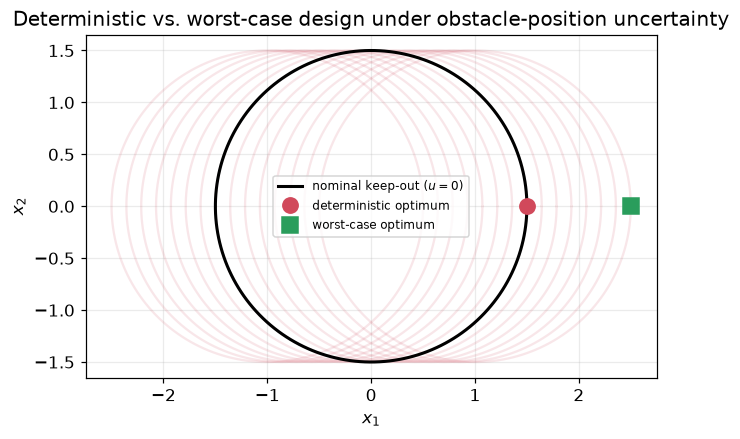

In [4]:
f = lambda x: x[0] ** 2 + x[1] ** 2
x0 = [3.0, 0.0]

res_det = minimize(f, x0=x0, constraints={"type": "ineq", "fun": lambda x: -h(0.0, x)}, method="SLSQP")
res_wc = minimize(f, x0=x0, constraints={"type": "ineq", "fun": lambda x: -worst_case_h_numeric(x)}, method="SLSQP")

print(f"deterministic (nominal u=0) optimum: x = [{res_det.x[0]:.4f}, {res_det.x[1]:.4f}],  f = {res_det.fun:.4f}")
print(f"worst-case (u in [{u_L},{u_U}]) optimum: x = [{res_wc.x[0]:.4f}, {res_wc.x[1]:.4f}],  f = {res_wc.fun:.4f}")
print(f"\nprice of the worst-case guarantee: f_wc / f_det = {res_wc.fun / res_det.fun:.3f}x")

theta = np.linspace(0, 2 * np.pi, 200)
fig, ax = plt.subplots(figsize=(6.2, 6.2))
for uu in np.linspace(u_L, u_U, 15):
    ax.plot(uu + r * np.cos(theta), r * np.sin(theta), color=COLORS["sweep"])
ax.plot(0 + r * np.cos(theta), r * np.sin(theta), color="black", lw=2, label="nominal keep-out ($u=0$)")
ax.plot(*res_det.x, "o", color=COLORS["det"], ms=10, label="deterministic optimum")
ax.plot(*res_wc.x, "s", color=COLORS["wc"], ms=10, label="worst-case optimum")
ax.set_aspect("equal")
ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$")
ax.set_title("Deterministic vs. worst-case design under obstacle-position uncertainty")
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

The pale circles trace the swept keep-out region as the obstacle center ranges
over $[u_L,u_U]$ -- a "stadium" shape. The worst-case optimum sits outside all of
them; the deterministic optimum, sized only against the nominal $u=0$ circle,
does not need to.

---
## 4. Checking the guarantee, and its price

> **Predict:** will the deterministic optimum actually violate the keep-out
> constraint for *some* $u\in[u_L,u_U]$, or does it happen to stay clear anyway?

In [5]:
u_grid = np.linspace(u_L, u_U, 401)
h_det = np.array([h(uu, res_det.x) for uu in u_grid])
h_wc = np.array([h(uu, res_wc.x) for uu in u_grid])

tol = 1e-4  # SLSQP's own constraint tolerance -- the worst-case optimum sits exactly ON the
            # boundary by construction, so a tight numerical zero is not attainable
print(f"deterministic optimum: max_u h(u,x) = {h_det.max():.5f}  "
      f"(feasible for every u? {h_det.max() <= tol})")
print(f"worst-case optimum:    max_u h(u,x) = {h_wc.max():.5f}  "
      f"(feasible for every u? {h_wc.max() <= tol})")

U_samples = rng.uniform(u_L, u_U, 300_000)
feas_frac_det = np.mean(h(U_samples, res_det.x) <= 0)
print(f"\nif U ~ Uniform[{u_L},{u_U}] were actually the true distribution:")
print(f"  P(deterministic optimum feasible) = {feas_frac_det:.3f}")
print(f"  (worst-case optimum is feasible with probability 1.000 by construction)")

deterministic optimum: max_u h(u,x) = 2.00000  (feasible for every u? False)
worst-case optimum:    max_u h(u,x) = 0.00001  (feasible for every u? True)

if U ~ Uniform[-1.0,1.0] were actually the true distribution:
  P(deterministic optimum feasible) = 0.500
  (worst-case optimum is feasible with probability 1.000 by construction)


The deterministic optimum is infeasible for part of the interval (it was only
sized against $u=0$), while the worst-case optimum is feasible everywhere, by
construction. But the last two printed lines make the trade-off concrete: *if*
$U$ actually turned out to be uniformly distributed over the interval, the
deterministic design would already be feasible most of the time -- the worst-case
design pays its extra cost (Section 3's ratio) to protect against the rest,
without knowing (or assuming) how likely that "rest" really is.

---
## Takeaways

1. Worst-case (min-max) optimization is a genuine *nested* optimization: the
   constraint value the outer solver sees is itself the result of an inner
   maximization over the uncertainty set -- built here with `minimize_scalar`
   inside the outer `minimize`'s constraint function.
2. When a constraint is convex in the uncertain parameter, its worst case sits at
   an interval endpoint (Section 1); when it is concave, the worst case can be
   interior to the interval (Section 2) -- know which case you are in before
   assuming "just check the endpoints" is enough.
3. Guaranteeing feasibility for *every* value in an interval costs more than
   optimizing for the nominal value alone -- quantified here as a cost ratio.
4. If a probability distribution over the uncertain parameter can actually be
   justified, RBDO or RDO (previous notebooks) will typically recover much of
   that lost performance, since they only defend against the *likely* range, not
   the interval's full extreme -- worst-case optimization is the right tool
   specifically when no such distribution can be justified.

## Classroom exercises

1. Widen $[u_L,u_U]$ and see how quickly the worst-case cost grows relative to
   the deterministic cost.
2. Add a second uncertain interval on the radius $r$ and extend the inner
   maximization to two uncertain parameters.
3. Replace the interval on $u$ with a 2-standard-deviation probabilistic bound
   and compare the resulting design to a reliability-based one from
   `L14_reliability_index_and_form.ipynb`.